# Simulazione MC di frange di intensità luminosità - Giornata 2
## Fase Preliminare
In questa fase preliminare settiamo tutto il necessario per il fitting dei dati ottenuti nella scorsa prova.

In [50]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit
import pandas as pd

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
ARANCIONE = "#FFA500"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)
rng = np.random.default_rng(120)

def f(x, B, I0, alpha, delta):
    return B + I0 * np.sinc(alpha * x / np.pi) ** 2 * np.cos(delta * x) ** 2

def poisson(x, B, I0, alpha, delta):
    y = rng.poisson(f(x, B, I0, alpha, delta))
    sigma_y = np.where(y == 0, 1, np.sqrt(y))
    return y, sigma_y

def fit(f, x, y, sigma_y, p0, lower, upper):
    popt, pcov = curve_fit(f, x, y, 
                       p0=p0, 
                       sigma=sigma_y, 
                       absolute_sigma=True, 
                       maxfev=100000, 
                       bounds=(lower, upper))
    return popt, pcov

## Attività 1
Nella prima attività vogliamo leggere il file csv `dati.csv` e verificare che gli array abbiano la stessa lunghezza, contengano valori finiti, abbiano incertezze positive e posizioni
ordinate.
Dopodichè rappresentiamo i *dati con barra di errore* (per ora senza fit).

Il numero di punti è: 161
I valori di x, y e sigma_y sono tutti finiti: True, True, True
Le incertezze sono tutte positive: True
Le posizioni sono ordinate: True
Intervallo di x: [-5.0, 5.0]
Intervallo di y: [13.0, 451.0]
Intervallo di sigma_y: [3.605551275463989, 21.236760581595302]


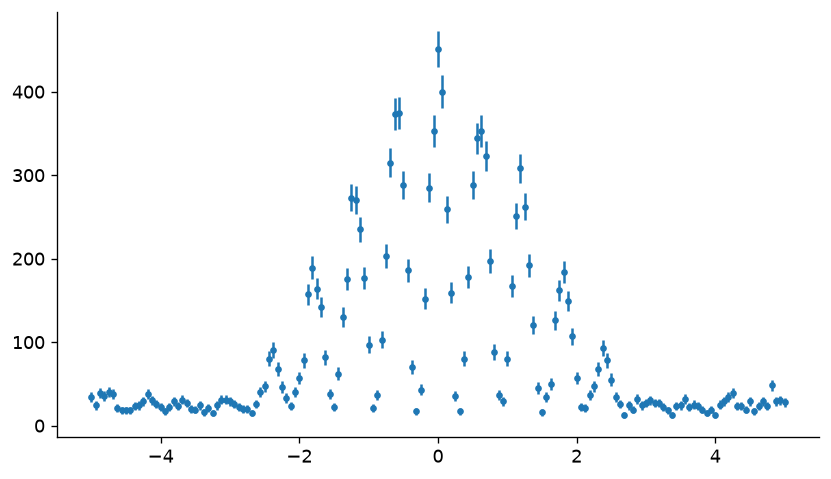

In [51]:
dati = np.genfromtxt(
"dati.csv",
delimiter=",",
names=True
)
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

print(f"Il numero di punti è: {len(x)}")
print(f"I valori di x, y e sigma_y sono tutti finiti: {np.all(np.isfinite(x))}, {np.all(np.isfinite(y))}, {np.all(np.isfinite(sigma_y))}")
print(f"Le incertezze sono tutte positive: {np.all(sigma_y > 0)}")
print(f"Le posizioni sono ordinate: {np.all(np.diff(x) > 0)}")
print(f"Intervallo di x: [{np.min(x)}, {np.max(x)}]")
print(f"Intervallo di y: [{np.min(y)}, {np.max(y)}]")
print(f"Intervallo di sigma_y: [{np.min(sigma_y)}, {np.max(sigma_y)}]")

fig, ax = plt.subplots()
ax.errorbar(x, y, yerr=sigma_y, fmt=".", label="Simulazione dati con errori")
plt.show()

## Attività 2
Stimiamo ora i parametri iniziali (valori plausibili e dentro i bounds) tenendo conto di:
$$ B^{(0)} \simeq mediana(y_{esterni}) $$
$$ I_0^{(0)} \simeq max(y) - B^{(0)} $$

In [52]:
from termios import B0


B_0 = np.median(y[np.abs(x) > 2.5])
I0_0 = np.max(y) - B_0
alpha_0 = 1
delta_0 = 5

# bounds
lower = [0.0, 0.0, 0.10, 1.0] # B0 I0 alpha delta
upper = [np.inf, np.inf, 3.0, 12.0]

if(B_0 < lower[0] or B_0 > upper[0]):
    print(f"Il valore di B_0 = {B_0} è fuori dai limiti [{lower[0]}, {upper[0]}]")
if(I0_0 < lower[1] or I0_0 > upper[1]):
    print(f"Il valore di I0_0 = {I0_0} è fuori dai limiti [{lower[1]}, {upper[1]}]")    
if(alpha_0 < lower[2] or alpha_0 > upper[2]):
    print(f"Il valore di alpha_0 = {alpha_0} è fuori dai limiti [{lower[2]}, {upper[2]}]")
if(delta_0 < lower[3] or delta_0 > upper[3]):
    print(f"Il valore di delta_0 = {delta_0} è fuori dai limiti [{lower[3]}, {upper[3]}]")

print((f"B_0 = {B_0} bounds = [{lower[0]}, {upper[0]}]"))
print((f"I0_0 = {I0_0} bounds = [{lower[1]}, {upper[1]}]"))
print((f"alpha_0 = {alpha_0} bounds = [{lower[2]}, {upper[2]}]"))
print((f"delta_0 = {delta_0} bounds = [{lower[3]}, {upper[3]}]"))


B_0 = 24.0 bounds = [0.0, inf]
I0_0 = 427.0 bounds = [0.0, inf]
alpha_0 = 1 bounds = [0.1, 3.0]
delta_0 = 5 bounds = [1.0, 12.0]


## Attività 3
Eseguiamo ora il fit a partire dai parametri appena definiti, ottenendo i parametri ottimizati e la matrice di covarianza. Proseguiamo con il calcolo delle incertezze di ogni parametro ottenute dalla matrice di covarianza: 
$$ u(\theta_j) = \sqrt{(C_\theta)_{jj}} $$
Infine calcoliamo la matrice di correlazione e la rappresentiamo con una mappa di colore.
$$ \rho_{ij} = \frac{ (C_\theta)_{ij} }{ \sqrt{ (C_\theta)_{ii} (C_\theta)_{jj} } } $$

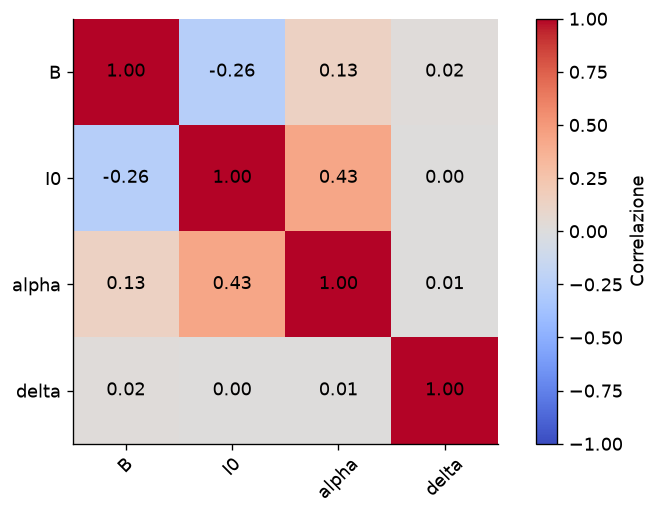

In [53]:
# fit the model to the data
p0 = [B_0, I0_0, alpha_0, delta_0]
popt, pcov = fit(f, x, y, sigma_y, p0, lower, upper)

# optimal parameters and their uncertainties
optimal_B, optimal_I0, optimal_alpha, optimal_delta = popt
optimal_B_err, optimal_I0_err, optimal_alpha_err, optimal_delta_err = np.sqrt(np.diag(pcov))
corr = pcov / np.outer(np.sqrt(np.diag(pcov)), np.sqrt(np.diag(pcov)))

# plot the correlation matrix
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
labels = ["B", "I0", "alpha", "delta"]
plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)
plt.colorbar(label="Correlazione")
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr[i, j]:.2f}",
                 ha="center", va="center")

plt.show()


## Attività 4
Calcoliamo e stampiamo i seguenti valori:
$$ r_i = y_i - f(x_j; \hat\theta) $$
$$ \rho_i = \frac{r_i}{\sigma_{y_i}} $$
$$ \chi^2 = \sum_i \rho_i^2 $$
$$ \nu = N - 4 $$
$$ \chi_{rid}^2 = \frac{\chi^2}{\nu} $$
Dopodiche mostriamo due figure:
- una con i dati, le barre di errore e il fit
- una con i pull.

chi2 = 169.41, dof = 157, chi2_red = 1.08, p-value = 0.2358


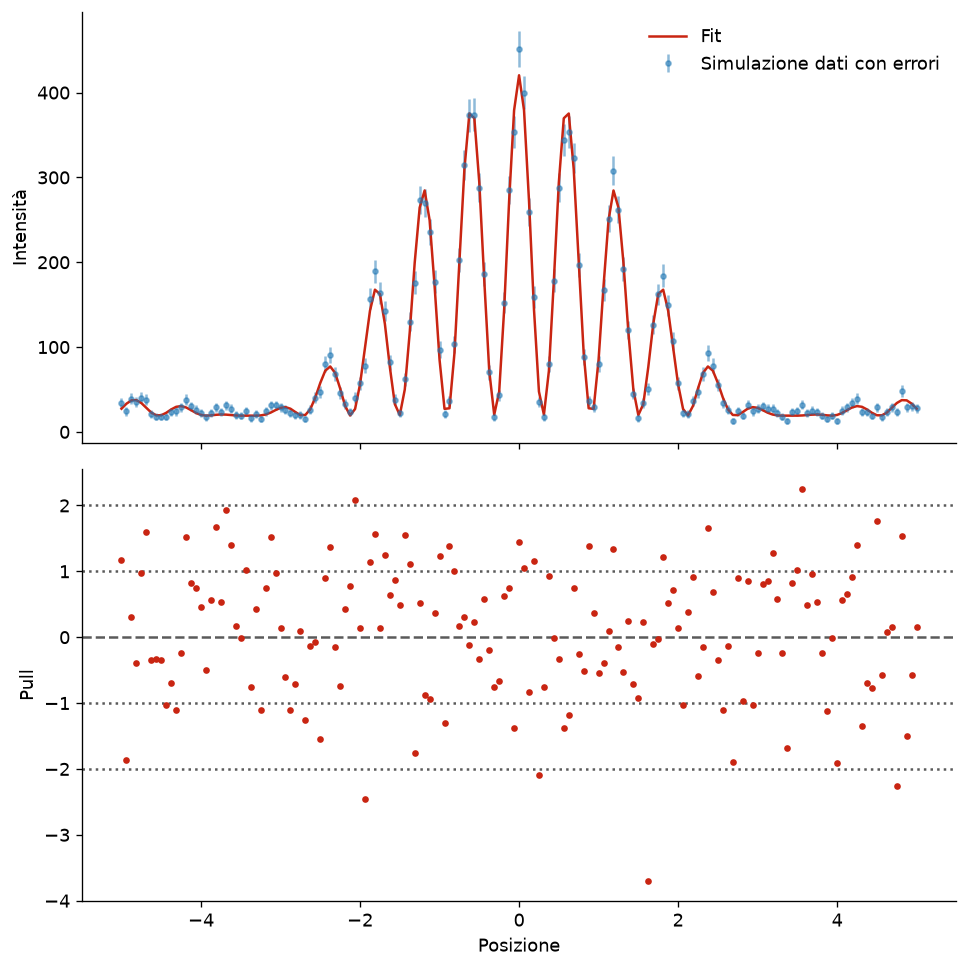

In [54]:
r = y - f(x, *popt)
pull = r / sigma_y
chi2 = np.sum(pull**2)
dof = len(x) - len(popt)
chi2_red = chi2 / dof
p_value = stats.chi2.sf(chi2, dof)
print(f"chi2 = {chi2:.2f}, dof = {dof}, chi2_red = {chi2_red:.2f}, p-value = {p_value:.4f}")

fig, ax = plt.subplots(2, 1, figsize=(8.2, 8.2), sharex=True)
ax[0].errorbar(x, y, yerr=sigma_y, fmt=".", alpha=0.5, label="Simulazione dati con errori")
ax[0].plot(x, mu(x, *popt), color=ROSSO, label="Fit")
ax[0].set_ylabel("Intensità")
ax[0].legend()
ax[1].errorbar(x, pull, fmt=".", color=ROSSO)
ax[1].axhline(0, color=GRIGIO, linestyle="--")
ax[1].axhline(1, color=GRIGIO, linestyle=":")
ax[1].axhline(-1, color=GRIGIO, linestyle=":")
ax[1].axhline(2, color=GRIGIO, linestyle=":")
ax[1].axhline(-2, color=GRIGIO, linestyle=":")
ax[1].set_xlabel("Posizione")
ax[1].set_ylabel("Pull")
plt.tight_layout()


# Attività 5
Ripetiamo ora il fitting utilizzando una versione del modello priva dell'inviluppo:
$$ f_{rid}(x) = B + I_0 cos^2(\delta x) $$

chi2 = 7347.65, dof = 158, chi2_red = 46.50, p-value = 0.0000


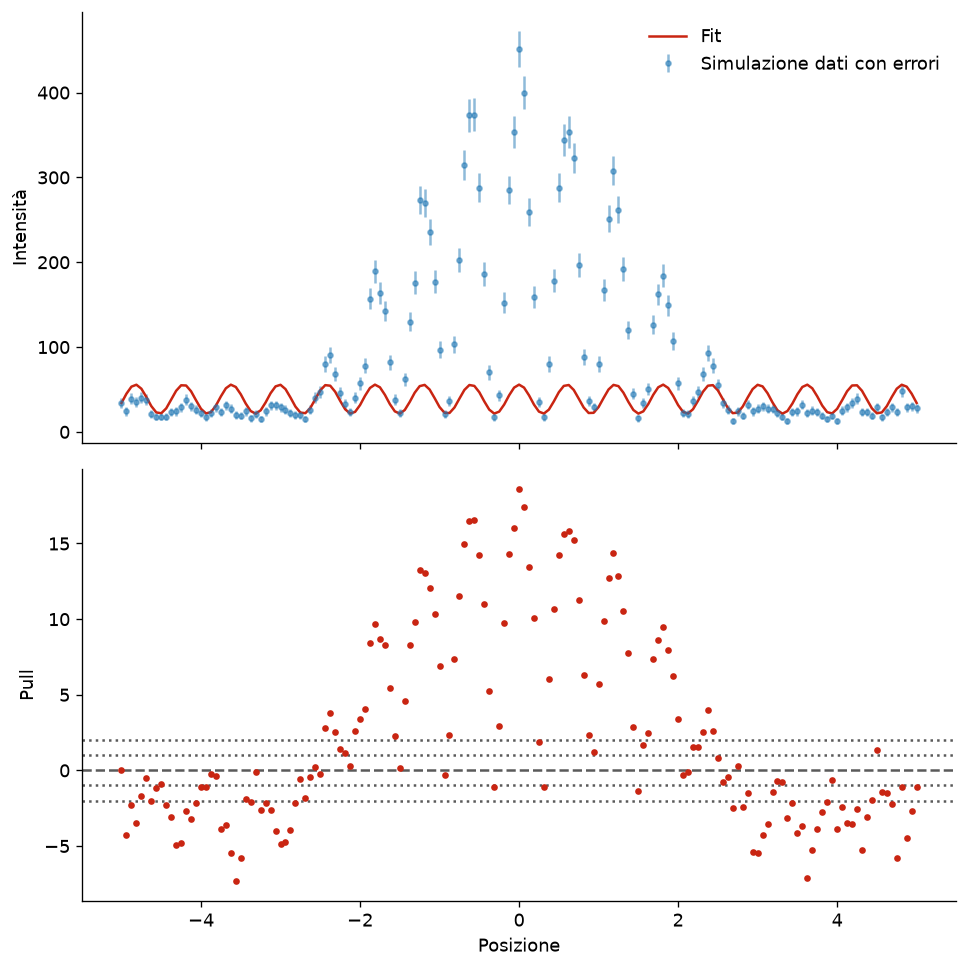

In [57]:
def f_rid(x, B, I0, delta):
    return B + I0 * np.cos(delta * x) ** 2

p0_rid = [B_0, I0_0, delta_0]
lower_rid = [0.0, 0.0, 1.0] # B I0 delta
upper_rid = [np.inf, np.inf, 12.0] # B I0 delta
popt_rid, pcov_rid = fit(f_rid, x, y, sigma_y,p0_rid, lower_rid, upper_rid)

r = y - f_rid(x, *popt_rid)
pull = r / sigma_y
chi2 = np.sum(pull**2)
dof = len(x) - len(popt_rid)
chi2_red = chi2 / dof
p_value = stats.chi2.sf(chi2, dof)
print(f"chi2 = {chi2:.2f}, dof = {dof}, chi2_red = {chi2_red:.2f}, p-value = {p_value:.4f}")

fig, ax = plt.subplots(2, 1, figsize=(8.2, 8.2), sharex=True)
ax[0].errorbar(x, y, yerr=sigma_y, fmt=".", alpha=0.5, label="Simulazione dati con errori")
ax[0].plot(x, f_rid(x, *popt_rid), color=ROSSO, label="Fit")
ax[0].set_ylabel("Intensità")
ax[0].legend()
ax[1].errorbar(x, pull, fmt=".", color=ROSSO)
ax[1].axhline(0, color=GRIGIO, linestyle="--")
ax[1].axhline(1, color=GRIGIO, linestyle=":")
ax[1].axhline(-1, color=GRIGIO, linestyle=":")
ax[1].axhline(2, color=GRIGIO, linestyle=":")
ax[1].axhline(-2, color=GRIGIO, linestyle=":")
ax[1].set_xlabel("Posizione")
ax[1].set_ylabel("Pull")
plt.tight_layout()